In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import math
import sys
import ast
import os
import matplotlib.patheffects as path_effects
sys.path.append('../')
from utils.Evaluation.calculate_metrics import calculate_scores
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as path_effects
sns.set_style(style='whitegrid')  # Better background
from collections import defaultdict, Counter
from typing import List, Tuple, Dict
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import sem
from matplotlib.cm import get_cmap
import colorsys
import numpy as np
import matplotlib.pyplot as plt
import ast
import statistics

In [2]:
def extract_params(model_name):
    import re
    match = re.search(r'([\d.]+)[bB]', model_name)
    if match:
        return float(match.group(1))
    return 1000  # Default if no match

def count_tries(row):
    path = row['path']
    cypher_corrector_freq = path.count('cypher_corrector')
    # if 'schema_retriever' in path:
    #     # KG valid with full schema
    #     if 'output_generator' in path:
    #         count = cypher_corrector_freq - 5
    #     # Unvailable Output
    #     else:
    #         count = None
    # # KG Valid with filtered schema
    # else:
    count = cypher_corrector_freq
    return count

def remove_duplicates(row):
    unique_elements =row[:len(row) // 2]
    return unique_elements

def extract_error_types_as_lists(nested_list):
    return [[s.split(':')[0].strip() for s in sublist] for sublist in nested_list]

def extract_error_types(nested_list):
    return [s.split(':')[0] for sublist in nested_list for s in sublist]

def calculate_dicts_with_usage(source_directory,extended=True):
    dict_with_models={}
    for name in os.listdir(source_directory):
        folder_path = os.path.join(source_directory, name)
        if os.path.isdir(folder_path):
            # “name” is an immediate folder
            print(f"Entering folder: {folder_path}")
            # do your work here, e.g. list files inside:
            for file in os.listdir(folder_path):
                file_path = os.path.join(folder_path, file)
                if file.endswith('_usage.xlsx'):
                    print(f"Entering file: {file}")
                    df_all = pd.read_excel(file_path)
                    
                    if 'Sustain' in file_path:
                        df = df_all
                    else:
                        df = df_all[df_all['Original_KG_Valid']==True].reset_index(drop=True)
                    
                    if extended:
                        list_columns = ['path','cypher_errors_history', 'cypher_errors']
                        for col in list_columns:
                            df[col] = df[col].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
                        
                        # Extract error types from cypher_errors_history
                        df['cypher_errors_history'] = df['cypher_errors_history'].apply(remove_duplicates)
                        df['flattened_cypher_errors_history'] = df['cypher_errors_history'].apply(extract_error_types)
                        df['cypher_errors_codes_history'] = df['cypher_errors_history'].apply(extract_error_types_as_lists)
                        # df['cypher_errors_codes_with_categories'] = df['cypher_errors_codes_history'].apply(map_errors_codes_to_categories)
                        # df['cypher_errors_with_categories'] = df['cypher_errors_history'].apply(map_errors_to_categories)
                        
                    # For rows that isKG_Valid_correct is not present, we calculate it
                    # if 'is_KG_Valid' not in df.columns:
                    #     df['is_KG_Valid'] = (
                    #                                     (df['Schema Valid'] == 1) &
                    #                                     ((df['Properties Valid'] == 1) | df['Properties Valid'].isna()) &
                    #                                     (df['Syntax Valid'] == True)
                    #                                 )
                    #     df['is_KG_Valid'] = df['is_KG_Valid'].astype(bool)   
                    model_name = file.split('.')[0]
                    model_name = model_name.replace('openrouter_', '')
                    model_name = model_name.replace('_local', '')
                    dict_with_models[model_name] = df        

    return dict_with_models

In [3]:
# SustainDataset
models_mapping = {
    'gpt_4o':'gpt4o', 
    'llama3_2_3b':'Llama-3.2-3B-Instruct',
    'qwen2_5_7b':'Qwen2.5-7B-Instruct',
    'qwen2_5_Coder_32b':'Qwen2.5-Coder-32B-Instruct',
    'qwen2_5_72b':'Qwen2.5-72B-Instruct',
}

dataset = 'SustainDataset'

In [4]:
#Get all the dataframes with the results thate nd in _usage.xlsx
extended_dfs_dict = calculate_dicts_with_usage("./extended_workflow/Outputs_Evaluation/"+dataset,extended=True)
extended_dfs_dict = dict(sorted(extended_dfs_dict.items(), key=lambda item: extract_params(item[0])))
extended_dfs_dict.keys()
basic_dfs_dict = calculate_dicts_with_usage("./basic_workflow/Outputs_Evaluation/"+dataset,extended=False)
basic_dfs_dict = dict(sorted(basic_dfs_dict.items(), key=lambda item: extract_params(item[0])))
basic_dfs_dict.keys()
langgraph_dfs_dict = calculate_dicts_with_usage("./langgraph_workflow/Outputs_Evaluation/"+dataset,extended=False)
langgraph_dfs_dict = dict(sorted(langgraph_dfs_dict.items(), key=lambda item: extract_params(item[0])))
langgraph_dfs_dict.keys()

Entering folder: ./extended_workflow/Outputs_Evaluation/SustainDataset\gpt_4o
Entering file: gpt_4o_usage.xlsx
Entering folder: ./extended_workflow/Outputs_Evaluation/SustainDataset\llama3_2_3b
Entering file: llama3_2_3b_usage.xlsx
Entering folder: ./extended_workflow/Outputs_Evaluation/SustainDataset\qwen2_5_72b
Entering file: qwen2_5_72b_usage.xlsx
Entering folder: ./extended_workflow/Outputs_Evaluation/SustainDataset\qwen2_5_7b
Entering file: qwen2_5_7b_usage.xlsx
Entering folder: ./extended_workflow/Outputs_Evaluation/SustainDataset\qwen2_5_Coder_32b
Entering file: qwen2_5_Coder_32b_usage.xlsx
Entering folder: ./basic_workflow/Outputs_Evaluation/SustainDataset\gpt_4o
Entering file: gpt_4o_usage.xlsx
Entering folder: ./basic_workflow/Outputs_Evaluation/SustainDataset\llama3_2_3b
Entering file: llama3_2_3b_usage.xlsx
Entering folder: ./basic_workflow/Outputs_Evaluation/SustainDataset\llama3_2_3b_local
Entering folder: ./basic_workflow/Outputs_Evaluation/SustainDataset\qwen2_5_72b
Ent

dict_keys(['gpt_4o_usage'])

## For each iter

In [6]:
stats = []

for phase, model_dict in [
    ('Basic Workflow', basic_dfs_dict),
    ('Extended Workflow', extended_dfs_dict),
    ('Langgraph Workflow', langgraph_dfs_dict)
]:
    for model_name, df in model_dict.items():
        if phase == 'Extended Workflow':
            df['Iteration'] = df.apply(count_tries, axis=1)

            for col in ["total_tokens", "completion_tokens", "prompt_tokens"]:
                if col in df.columns:
                    if isinstance(df[col].iloc[0], str):
                        df[col] = df[col].apply(ast.literal_eval)
                    # compute sum ignoring -1
                    df[col + '_sum'] = df[col].apply(lambda x: sum(int(v) for v in x if int(v) != -1))

            # Now compute metrics **per iteration**
            for iteration, iter_df in df.groupby('Iteration'):
                metrics = {
                    'Median Time (s) ± iqr':  f"{round(iter_df['eval_time_s'].median(), 2)} ± {(iter_df['eval_time_s'].quantile(0.75) - iter_df['eval_time_s'].quantile(0.25)):.2f}" if not iter_df['eval_time_s'].empty else "N/A",
                    'Median Prompt Tokens ± iqr': f"{iter_df['prompt_tokens_sum'].median():.2f} ± {(iter_df['prompt_tokens_sum'].quantile(0.75) - iter_df['prompt_tokens_sum'].quantile(0.25)):.2f}" if 'prompt_tokens_sum' in iter_df.columns else "N/A"
                }

                for metric, value in metrics.items():
                    stats.append({
                        'Model': models_mapping[model_name.rstrip('_usage')],
                        'Phase': phase,
                        'Iteration': iteration,
                        'Metric': metric,
                        'Count': value
                    })

# Create DataFrame
melted_df = pd.DataFrame(stats)
melted_df['Params'] = melted_df['Model'].apply(extract_params)
melted_df = melted_df.sort_values(by=['Params'])


df_wide = melted_df.pivot_table(
    index='Model',
    columns=['Metric','Iteration'],
    values='Count',
    aggfunc='first'
)
df_wide = df_wide.reset_index()
df_wide['Params'] = df_wide.Model.apply(extract_params)
df_wide = df_wide.sort_values(by=['Params'])


df_pivot = melted_df.pivot_table(
    index=['Metric', 'Iteration'],
    columns='Model',
    values='Count',
    aggfunc='first'  # or 'mean' if duplicates exist
).reset_index()

df_pivot

Model,Metric,Iteration,Llama-3.2-3B-Instruct,Qwen2.5-72B-Instruct,Qwen2.5-7B-Instruct,Qwen2.5-Coder-32B-Instruct,gpt4o
0,Median Prompt Tokens ± iqr,0,740.00 ± 1496.00,1354.00 ± 2792.00,718.00 ± 1229.00,1354.00 ± 1967.00,1342.50 ± 2876.00
1,Median Prompt Tokens ± iqr,1,4796.00 ± 3864.00,2956.00 ± 3634.00,4039.50 ± 5888.75,9009.50 ± 1984.25,3877.00 ± 2560.50
2,Median Prompt Tokens ± iqr,2,7430.50 ± 5772.50,13485.00 ± 0.00,10252.50 ± 5750.50,15226.50 ± 6219.50,13947.00 ± 0.00
3,Median Prompt Tokens ± iqr,3,13886.50 ± 7289.50,21530.00 ± 0.00,11494.50 ± 6816.50,4835.50 ± 1299.50,NaN
4,Median Prompt Tokens ± iqr,5,6482.00 ± 0.00,NaN,3693.00 ± 0.00,NaN,NaN
5,Median Prompt Tokens ± iqr,6,43146.00 ± 0.00,NaN,NaN,NaN,NaN
6,Median Prompt Tokens ± iqr,7,29955.00 ± 0.00,NaN,NaN,NaN,NaN
7,Median Prompt Tokens ± iqr,8,NaN,NaN,60459.00 ± 0.00,NaN,NaN
8,Median Prompt Tokens ± iqr,9,NaN,46999.00 ± 0.00,NaN,NaN,NaN
9,Median Prompt Tokens ± iqr,10,53120.00 ± 16284.50,53947.00 ± 0.00,53807.00 ± 19476.00,52932.00 ± 0.00,NaN


In [ ]:
# #Add number of iterations to extended dataframews
# for model_name, df in extended_dfs_dict.items():
#     df['Iteration'] = df.apply(count_tries, axis=1)
#     df['Group'] = np.where(
#     (df['is_KG_Valid_correct_with_full_schema'] == False) & (df['is_KG_Valid_correct'] == True),
#     'KG Valid Queries (Filtered Schema)',
#     np.where(df['is_KG_Valid_correct_with_full_schema'] == True,'KG Valid Queries (Full Schema)' , 'Unavailable Output')
#     )
#     df['Model'] = models_mapping[model_name.rstrip('_usage')]

# for model_name, df in basic_dfs_dict.items():
#     df['Model'] = models_mapping[model_name.rstrip('_usage')]

# for model_name, df in langgraph_dfs_dict.items():
#     df['Model'] = models_mapping[model_name.rstrip('_usage')]

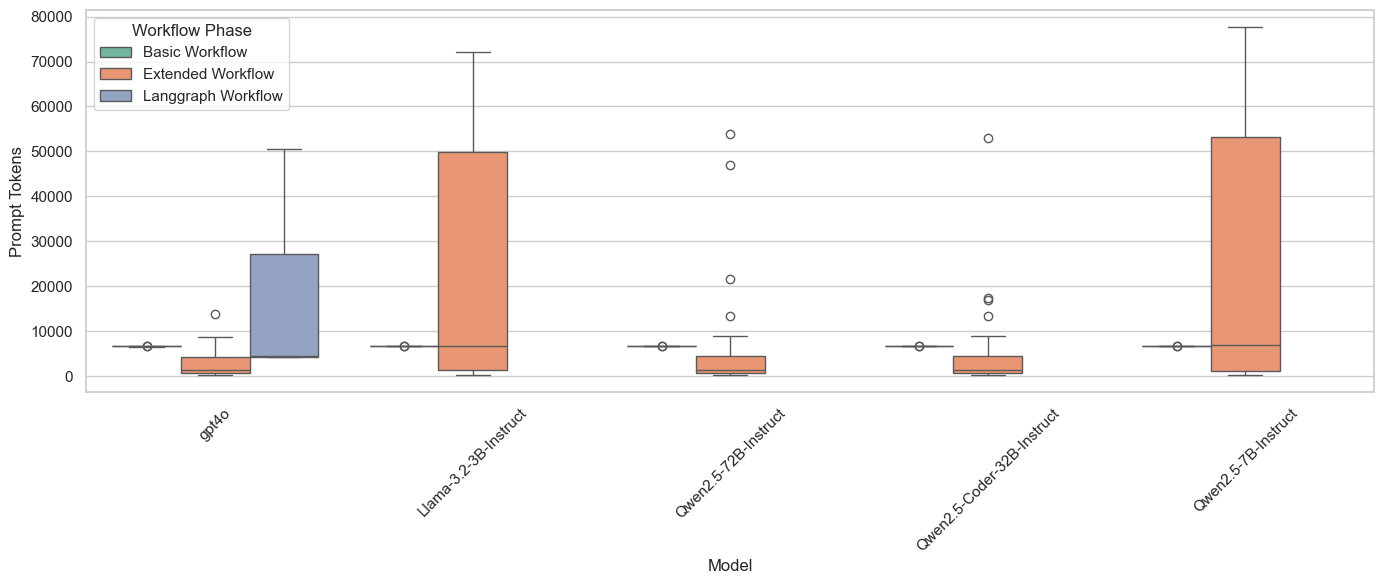

In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import ast
import numpy as np

# List your three workflows
workflows = [
    ('Basic Workflow', basic_dfs_dict),
    ('Extended Workflow', extended_dfs_dict),
    ('Langgraph Workflow', langgraph_dfs_dict)
]

# Prepare a unified plotting dataframe
plot_data = []

for phase_name, workflow_dict in workflows:
    for model_name, df in workflow_dict.items():
        for col in ["total_tokens", "completion_tokens", "prompt_tokens"]:
            if col in df.columns:
                if isinstance(df[col].iloc[0], str):
                    df[col] = df[col].apply(ast.literal_eval)
                # ignore -1
                token_sums = df[col].apply(lambda x: sum(int(v) for v in x if int(v) != -1))
                df[col + '_sum'] = token_sums
        # Make sure 'prompt_tokens_sum' exists
        if 'prompt_tokens_sum' in df.columns:
            temp_df = df[['prompt_tokens_sum']].copy()
            temp_df['Model'] = models_mapping.get(model_name.rstrip('_usage'), model_name)
            temp_df['Phase'] = phase_name
            plot_data.append(temp_df)
        else:
            print(f"Skipping {model_name} in {phase_name} — no prompt_tokens_sum column.")

# Concatenate everything
if len(plot_data) == 0:
    raise ValueError("No data found to plot!")
plot_df = pd.concat(plot_data, ignore_index=True)

# Optional: sort models by median prompt tokens
median_order = plot_df.groupby('Model')['prompt_tokens_sum'].median().sort_values().index

# Boxplot for Prompt Tokens
sns.set(style="whitegrid")
plt.figure(figsize=(14,6))
ax = sns.boxplot(
    x='Model',
    y='prompt_tokens_sum',
    hue='Phase',
    data=plot_df,
    order=median_order,
    palette='Set2',
    showfliers=True
)

# Annotate median values above boxes
for i, patch in enumerate(ax.patches):
    # Compute which model and phase this patch corresponds to
    num_phases = plot_df['Phase'].nunique()
    model_idx = i // num_phases
    phase_idx = i % num_phases
    model_name = median_order[model_idx]
    phase_name = plot_df['Phase'].unique()[phase_idx]
    
    # Get median value for this model & phase
    median_val = plot_df[(plot_df['Model']==model_name) & (plot_df['Phase']==phase_name)]['prompt_tokens_sum'].median()
    
    # X-coordinate of the box
    # x = patch.get_x() + patch.get_width()/2
    y = median_val
    # ax.text(x, y + 2, f'{median_val:.0f}', ha='center', fontsize=9, color='black')


# plt.title('Prompt Tokens-Comparison Across Workflows', fontsize=14)
plt.ylabel('Prompt Tokens')
plt.xlabel('Model')
plt.xticks(rotation=45)
plt.legend(title='Workflow Phase')
plt.tight_layout()
plt.show()


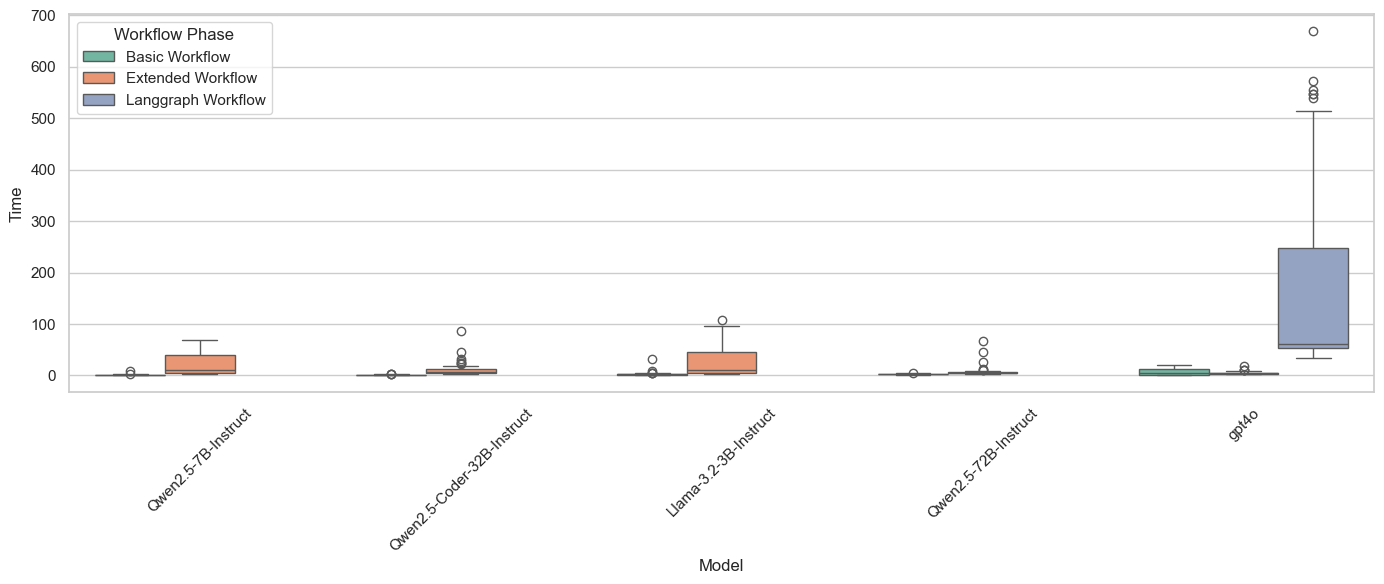

In [9]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import ast
import numpy as np

# List your three workflows
workflows = [
    ('Basic Workflow', basic_dfs_dict),
    ('Extended Workflow', extended_dfs_dict),
    ('Langgraph Workflow', langgraph_dfs_dict)
]

# Prepare a unified plotting dataframe
plot_data = []

for phase_name, workflow_dict in workflows:
    for model_name, df in workflow_dict.items():
        # Make sure 'prompt_tokens_sum' exists
        if 'eval_time_s' in df.columns:
            temp_df = df[['eval_time_s']].copy()
            temp_df['Model'] = models_mapping.get(model_name.rstrip('_usage'), model_name)
            temp_df['Phase'] = phase_name
            plot_data.append(temp_df)
        else:
            print(f"Skipping {model_name} in {phase_name} — no prompt_tokens_sum column.")

# Concatenate everything
if len(plot_data) == 0:
    raise ValueError("No data found to plot!")
plot_df = pd.concat(plot_data, ignore_index=True)

# Optional: sort models by median prompt tokens
median_order = plot_df.groupby('Model')['eval_time_s'].median().sort_values().index

# Boxplot for Prompt Tokens
sns.set(style="whitegrid")
plt.figure(figsize=(14,6))
ax = sns.boxplot(
    x='Model',
    y='eval_time_s',
    hue='Phase',
    data=plot_df,
    order=median_order,
    palette='Set2',
    showfliers=True
)

# Annotate median values above boxes
for i, patch in enumerate(ax.patches):
    # Compute which model and phase this patch corresponds to
    num_phases = plot_df['Phase'].nunique()
    model_idx = i // num_phases
    phase_idx = i % num_phases
    model_name = median_order[model_idx]
    phase_name = plot_df['Phase'].unique()[phase_idx]
    
    # Get median value for this model & phase
    median_val = plot_df[(plot_df['Model']==model_name) & (plot_df['Phase']==phase_name)]['eval_time_s'].median()
    
    # X-coordinate of the box
    # x = patch.get_x() + patch.get_width()/2
    y = median_val
    # ax.text(x, y + 2, f'{median_val:.0f}', ha='center', fontsize=9, color='black')


# plt.title('Prompt Tokens-Comparison Across Workflows', fontsize=14)
plt.ylabel('Time')
plt.xlabel('Model')
plt.xticks(rotation=45)
plt.legend(title='Workflow Phase')
plt.tight_layout()
plt.show()


In [12]:
stats = []
for phase, model_dict in [('Basic Workflow', basic_dfs_dict), ('Extended Workflow', extended_dfs_dict),('Langgraph Workflow', langgraph_dfs_dict)]:
    for model_name, df in model_dict.items():
        # df['Iteration'] = df.apply(count_tries, axis=1)
        # print(model_name)
        for col in ["total_tokens", "completion_tokens", "prompt_tokens"]:
            if col in df.columns:
                if isinstance(df[col].iloc[0], str):
                    df[col] = df[col].apply(ast.literal_eval)
                # ignore -1
                token_sums = df[col].apply(lambda x: sum(int(v) for v in x if int(v) != -1))
                df[col + '_sum'] = token_sums
        metrics = {
            'Median Time (s) ± iqr':  f"{round(df['eval_time_s'].median(), 2)} ± {(df['eval_time_s'].quantile(0.75) - df['eval_time_s'].quantile(0.25)):.2f}",
                # df['eval_time_s'].std(), 2)}",
            # 'Median Time (s) ± std':  f"{round(df['eval_time_s'].median(), 2)} ± {round(df['eval_time_s'].std(), 2)}",            
            # '(Min,Max Time (s))': (round(df['eval_time_s'].min(),2), round(df['eval_time_s'].max(),2)),
            # 'Mean Total Tokens ± std':  f"{round(df['total_tokens_sum'].mean(), 2)} ± {round(df['total_tokens_sum'].std(), 2)}",
            'Median Prompt Tokens ± iqr':  f"{df['prompt_tokens_sum'].median():.2f} ± {(df['prompt_tokens_sum'].quantile(0.75) - df['prompt_tokens_sum'].quantile(0.25)):.2f}",
            # 'Mean Completion Tokens ± std':  f"{round(df['completion_tokens_sum'].mean(), 2)} ± {round(df['completion_tokens_sum'].std(), 2)}",
            # '(Min,Max Time (s))': ', '.join(map(str, (
            #     round(df['eval_time_s'].min(), 2),
            #     round(df['eval_time_s'].max(), 2)
            # ))),
            # '(Min,Max Total Tokens)': ', '.join(map(str, (
            #     round(df['total_tokens_sum'].min(), 2),
            #     round(df['total_tokens_sum'].max(), 2)
            # ))),
            # '(Filtered,Full,Unavailable)': ', '.join(map(str, (
            #     round((len(df[df['Group'] == 'KG Valid Queries (Filtered Schema)'])/len(df)*100),2),
            #     round((len(df[df['Group'] == 'KG Valid Queries (Full Schema)'])/len(df)*100),2),
            #     round((len(df[df['Group'] == 'Unavailable Output'])/len(df)*100),2)
            # ))) if phase == 'Extended Workflow' else None,        
                  }
        for metric, count in metrics.items():
            stats.append({
                'Model': models_mapping[model_name.rstrip('_usage')],
                'Phase': phase,
                'Metric': metric,
                'Count': count
            })

# Create DataFrame
melted_df = pd.DataFrame(stats)
melted_df['Params'] = melted_df['Model'].apply(extract_params)
melted_df = melted_df.sort_values(by=['Params'])

df_pivoted = melted_df.pivot(index=['Model', 'Phase','Params'], columns='Metric', values='Count').reset_index()
df_pivoted = df_pivoted.sort_values(by=['Params','Model','Phase'])
df_pivoted = df_pivoted.drop('Params',axis=1)

In [13]:
df_wide = melted_df.pivot_table(
    index='Model',
    columns=['Metric', 'Phase'],
    values='Count',
    aggfunc='first'
)
df_wide = df_wide.reset_index()
df_wide['Params'] = df_wide.Model.apply(extract_params)
df_wide = df_wide.sort_values(by=['Params'])
df_wide
# Reset index to show 'Model' as a column

# Show
# df_wide.to_excel('computational_cost_analysis.xlsx')

Metric                       Model Median Prompt Tokens ± iqr  \
Phase                                          Basic Workflow   
0            Llama-3.2-3B-Instruct            6673.00 ± 11.00   
2              Qwen2.5-7B-Instruct            6792.50 ± 11.00   
3       Qwen2.5-Coder-32B-Instruct            6792.50 ± 11.00   
1             Qwen2.5-72B-Instruct            6792.50 ± 11.00   
4                            gpt4o            6629.00 ± 11.00   

Metric                                         Median Time (s) ± iqr  \
Phase    Extended Workflow  Langgraph Workflow        Basic Workflow   
0       6761.50 ± 48463.25                 NaN            1.9 ± 1.38   
2       6875.00 ± 52005.00                 NaN           0.92 ± 0.60   
3        1495.50 ± 3776.25                 NaN           1.24 ± 0.70   
1        1480.50 ± 3666.25                 NaN           2.65 ± 0.90   
4        1370.50 ± 3507.75  4440.50 ± 22879.50          5.72 ± 12.00   

Metric                                       Params  
Phase  Extended Workflow Langgraph Workflow          
0          10.59 ± 40.42                NaN     3.0  
2          11.39 ± 35.84                NaN     7.0  
3             7.5 ± 6.96                NaN    32.0  
1            4.97 ± 1.77                NaN    72.0  
4            4.28 ± 2.33     61.13 ± 192.75  1000.0

In [43]:
basic_stats = []
for model_name, df in basic_dfs_dict.items():
    print(model_name)
    if 'eval_time_s' in df.columns:
        basic_stats.append({
            "Model": df['Model'].iloc[0],
            "Type": "Basic",
            "Mean": round(df['eval_time_s'].mean(),2),
            "Median": round(df['eval_time_s'].median(),2),
            "Max": round(df['eval_time_s'].max(),2),
            "Min": round(df['eval_time_s'].min(),2),
            "Std": round(df['eval_time_s'].std(), 2),
            "Mean Iteration": None , # Not applicable for basic workflow
        })
        print('added successfully')

# Collect stats for extended
extended_stats = []
for model_name, df in extended_dfs_dict.items():
    if 'eval_time_s' in df.columns:
        mean_iteration = df['Iteration'].mean() if 'Iteration' in df.columns else None
        extended_stats.append({
            "Model": df['Model'].iloc[0],
            "Type": "Extended",
            "Mean": round(df['eval_time_s'].mean(),2),
            "Median": round(df['eval_time_s'].median(),2),
            "Max": round(df['eval_time_s'].max(),2),
            "Min": round(df['eval_time_s'].min(),2),
            "Std": round(df['eval_time_s'].std(), 2),
            "Mean Iteration": mean_iteration,
        })
        print('added successfully')

langgraph_stats = []
for model_name, df in langgraph_dfs_dict.items():
    if 'eval_time_s' in df.columns:
        mean_iteration = df['Iteration'].mean() if 'Iteration' in df.columns else None
        langgraph_stats.append({
            "Model": df['Model'].iloc[0],
            "Type": "LangGraph",
            "Mean": round(df['eval_time_s'].mean(),2),
            "Median": round(df['eval_time_s'].median(),2),
            "Max": round(df['eval_time_s'].max(),2),
            "Min": round(df['eval_time_s'].min(),2),
            "Std": round(df['eval_time_s'].std(), 2),
            "Mean Iteration": None, #not applicable for langgraph workflow
        })
    
        print('added successfully')

# Combine into a single DataFrame
stats_df = pd.DataFrame(basic_stats + extended_stats + langgraph_stats)
stats_df['Params'] = stats_df['Model'].apply(extract_params)
stats_df = stats_df.sort_values(["Params", "Type"]).reset_index(drop=True)
display(stats_df)

llama3_2_3b_usage
added successfully
qwen2_5_7b_usage
added successfully
qwen2_5_Coder_32b_usage
added successfully
qwen2_5_72b_usage
added successfully
gpt_4o_usage
added successfully
added successfully
added successfully
added successfully
added successfully
added successfully
added successfully


,Model,Type,Mean,Median,Max,Min,Std,Mean Iteration,Params
0,Llama-3.2-3B-Instruct,Basic,2.91,1.90,31.74,0.67,4.33,NaN,3.0
1,Llama-3.2-3B-Instruct,Extended,27.16,10.59,108.41,2.32,27.96,4.326923,3.0
2,Qwen2.5-7B-Instruct,Basic,1.21,0.92,8.78,0.38,1.20,NaN,7.0
3,Qwen2.5-7B-Instruct,Extended,21.68,11.39,68.67,2.12,19.95,4.596154,7.0
4,Qwen2.5-Coder-32B-Instruct,Basic,1.32,1.24,3.35,0.60,0.62,NaN,32.0
5,Qwen2.5-Coder-32B-Instruct,Extended,11.42,7.50,85.95,2.88,13.51,0.538462,32.0
6,Qwen2.5-72B-Instruct,Basic,2.69,2.65,4.87,1.24,0.76,NaN,72.0
7,Qwen2.5-72B-Instruct,Extended,7.65,4.97,66.99,3.09,10.59,0.519231,72.0
8,gpt4o,Basic,7.15,5.72,20.63,0.68,6.16,NaN,1000.0
9,gpt4o,Extended,5.13,4.28,18.93,2.35,2.85,0.096154,1000.0


In [29]:
basic_token_stats = []
for model_name, df in basic_dfs_dict.items():
    print(model_name)
    basic_stats = {"Model": df['Model'].iloc[0]}
    for col in ["total_tokens", "completion_tokens", "prompt_tokens"]:
        if col in df.columns:
            if isinstance(df[col].iloc[0], str):
                df[col] = df[col].apply(ast.literal_eval)
            # ignore -1
            token_sums = df[col].apply(lambda x: sum(int(v) for v in x if int(v) != -1))
            basic_stats["Type"] = "Basic"
            basic_stats[f"Mean {col}"] = round(token_sums.mean(), 2)
            basic_stats[f"Median {col}"] = round(token_sums.median(), 2)
            basic_stats[f"Max {col}"] = round(token_sums.max(), 2)
            basic_stats[f"Min {col}"] = round(token_sums.min(), 2)
            basic_stats[f"Std {col}"] = round(token_sums.std(), 2)
    basic_token_stats.append(basic_stats)
    print('added successfully')
basic_token_stats_df = pd.DataFrame(basic_token_stats)
print('added successfully')

extended_token_stats = []
for model_name, df in extended_dfs_dict.items():
    print(model_name)
    extended_stats = {"Model": df['Model'].iloc[0]}
    for col in ["total_tokens", "completion_tokens", "prompt_tokens"]:
        if col in df.columns:
            if isinstance(df[col].iloc[0], str):
                df[col] = df[col].apply(ast.literal_eval)
            # ignore -1
            token_sums = df[col].apply(lambda x: sum(int(v) for v in x if int(v) != -1))
            extended_stats["Type"] = "Extended"
            extended_stats[f"Mean {col}"] = round(token_sums.mean(), 2)
            extended_stats[f"Median {col}"] = round(token_sums.median(), 2)
            extended_stats[f"Max {col}"] = round(token_sums.max(), 2)
            extended_stats[f"Min {col}"] = round(token_sums.min(), 2)
            extended_stats[f"Std {col}"] = round(token_sums.std(), 2)
    extended_token_stats.append(extended_stats)
    print('added successfully')
basic_token_stats_df = pd.DataFrame(extended_token_stats)


langgraph_token_stats = []
for model_name, df in langgraph_dfs_dict.items():
    print(model_name)
    langgraph_stats = {"Model": df['Model'].iloc[0]}
    for col in ["total_tokens", "completion_tokens", "prompt_tokens"]:
        if col in df.columns:
            if isinstance(df[col].iloc[0], str):
                df[col] = df[col].apply(ast.literal_eval)
            # ignore -1
            token_sums = df[col].apply(lambda x: sum(int(v) for v in x if int(v) != -1))
            langgraph_stats["Type"] = "LangGraph"
            langgraph_stats[f"Mean {col}"] = round(token_sums.mean(), 2)
            langgraph_stats[f"Median {col}"] = round(token_sums.median(), 2)
            langgraph_stats[f"Max {col}"] = round(token_sums.max(), 2)
            langgraph_stats[f"Min {col}"] = round(token_sums.min(), 2)
            langgraph_stats[f"Std {col}"] = round(token_sums.std(), 2)
    langgraph_token_stats.append(langgraph_stats)
    print('added successfully')
basic_token_stats_df = pd.DataFrame(langgraph_token_stats)

token_stats_df = pd.DataFrame(basic_token_stats + extended_token_stats + langgraph_token_stats)
token_stats_df['Params'] = token_stats_df['Model'].apply(extract_params)
token_stats_df = token_stats_df.sort_values(["Params", "Type"]).reset_index(drop=True)
display(token_stats_df)


llama3_2_3b_usage
added successfully
qwen2_5_7b_usage
added successfully
qwen2_5_Coder_32b_usage
added successfully
qwen2_5_72b_usage
added successfully
gpt_4o_usage
added successfully
added successfully
llama3_2_3b_usage
added successfully
qwen2_5_7b_usage
added successfully
qwen2_5_Coder_32b_usage
added successfully
qwen2_5_72b_usage
added successfully
gpt_4o_usage
added successfully
gpt_4o_usage
added successfully


,Model,Type,Mean total_tokens,Median total_tokens,Max total_tokens,Min total_tokens,Std total_tokens,Mean completion_tokens,Median completion_tokens,Max completion_tokens,Min completion_tokens,Std completion_tokens,Mean prompt_tokens,Median prompt_tokens,Max prompt_tokens,Min prompt_tokens,Std prompt_tokens,Params
0,Llama-3.2-3B-Instruct,Basic,6757.15,6726.5,7693,6672,141.96,82.56,49.0,1011,11,139.64,6674.60,6673.0,6717,6661,9.80,3.0
1,Llama-3.2-3B-Instruct,Extended,24625.17,6870.0,72898,307,26522.56,425.00,132.5,2203,11,525.72,24200.17,6761.5,72021,284,26082.84,3.0
2,Qwen2.5-7B-Instruct,Basic,6863.75,6839.0,7488,6794,101.39,69.87,46.0,696,3,98.82,6793.88,6792.5,6840,6780,10.19,7.0
3,Qwen2.5-7B-Instruct,Extended,27838.60,6934.5,79029,290,29751.76,394.31,189.0,1571,9,428.91,27444.29,6875.0,77595,267,29385.67,7.0
4,Qwen2.5-Coder-32B-Instruct,Basic,6836.06,6832.0,6975,6794,35.78,42.17,38.5,135,12,27.65,6793.88,6792.5,6840,6780,10.19,32.0
5,Qwen2.5-Coder-32B-Instruct,Extended,4326.58,1522.5,53666,301,8028.47,78.44,41.0,734,13,120.48,4248.13,1495.5,52932,267,7923.44,32.0
6,Qwen2.5-72B-Instruct,Basic,6836.94,6834.5,6991,6794,36.70,43.06,40.5,151,12,28.16,6793.88,6792.5,6840,6780,10.19,72.0
7,Qwen2.5-72B-Instruct,Extended,4742.77,1505.0,55392,292,10173.93,97.88,41.0,1445,13,230.46,4644.88,1480.5,53947,267,9953.66,72.0
8,gpt4o,Basic,6672.58,6672.0,6781,6631,32.44,41.98,40.5,108,11,24.66,6630.60,6629.0,6673,6617,9.77,1000.0
9,gpt4o,Extended,2954.58,1448.5,34305,314,4848.67,49.81,38.5,306,12,48.07,2904.77,1410.5,33999,292,4808.94,1000.0


In [14]:
# Group by Model and Iteration, then aggregate eval_time_s
extended_stats_by_iter = []
for model_name, df in extended_dfs_dict.items():
    if 'eval_time_s' in df.columns and 'Iteration' in df.columns:
        grouped = df.groupby('Iteration')['eval_time_s'].agg(['mean', 'median', 'max', 'min']).reset_index()
        grouped['Model'] = df['Model'].iloc[0]
        extended_stats_by_iter.append(grouped)

# Concatenate all models' stats
stats_by_iter_df = pd.concat(extended_stats_by_iter, ignore_index=True)
stats_by_iter_df = stats_by_iter_df[['Model', 'Iteration', 'mean', 'median', 'max', 'min']]
stats_by_iter_df = stats_by_iter_df.rename(columns={
    'mean': 'Mean',
    'median': 'Median',
    'max': 'Max',
    'min': 'Min'
})
display(stats_by_iter_df)

,Model,Iteration,Mean,Median,Max,Min
0,Llama-3.2-3B-Instruct,0,3.248747,3.06800,6.4720,1.9942
1,Llama-3.2-3B-Instruct,1,6.035320,5.18310,8.2071,4.5235
2,Llama-3.2-3B-Instruct,2,8.358100,8.14490,10.0666,7.2042
3,Llama-3.2-3B-Instruct,3,11.296767,10.63900,14.0197,9.2316
4,Llama-3.2-3B-Instruct,5,18.620400,18.62040,18.6204,18.6204
5,Llama-3.2-3B-Instruct,6,28.454100,28.45410,30.9029,26.0053
6,Llama-3.2-3B-Instruct,7,26.720600,26.72060,26.7206,26.7206
7,Llama-3.2-3B-Instruct,9,41.631400,41.63140,41.6314,41.6314
8,Llama-3.2-3B-Instruct,10,54.074860,47.98980,97.6222,36.0620
9,Qwen2.5-Coder-32B-Instruct,0,5.648278,5.20405,15.1721,2.5343
